In [97]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import tarfile

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [5]:
import tensorflow as tf

dataset_url = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"

download_path = tf.keras.utils.get_file(
    "images.tar.gz",
    origin=dataset_url,
    extract=True
)

print(download_path)

791918971/791918971 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
/root/.keras/datasets/images_extracted


In [6]:
import os

base_dir = os.path.dirname(download_path)

print(base_dir)
print(os.listdir(base_dir))

/root/.keras/datasets
['images_extracted', 'images.tar.gz']


In [7]:
import os

image_dir = os.path.join(download_path, "images")

image_paths = []
labels = []

for filename in os.listdir(image_dir):

    if filename.endswith(".jpg"):

        image_path = os.path.join(image_dir, filename)

        # Remove extension
        name = filename.rsplit(".", 1)[0]

        # Remove the image number
        breed = name.rsplit("_", 1)[0]

        image_paths.append(image_path)
        labels.append(breed)

print("Total images:", len(image_paths))
print("First image:", image_paths[0])
print("First label:", labels[0])

Total images: 7390
First image: /root/.keras/datasets/images_extracted/images/leonberger_58.jpg
First label: leonberger


In [8]:
unique_breeds = sorted(set(labels))

print("Number of breeds:", len(unique_breeds))



Number of breeds: 37


In [9]:
breed_to_index = {
    breed: index
    for index, breed in enumerate(unique_breeds)
}

numeric_labels = [
    breed_to_index[label]
    for label in labels
]

print(breed_to_index)

{'Abyssinian': 0, 'Bengal': 1, 'Birman': 2, 'Bombay': 3, 'British_Shorthair': 4, 'Egyptian_Mau': 5, 'Maine_Coon': 6, 'Persian': 7, 'Ragdoll': 8, 'Russian_Blue': 9, 'Siamese': 10, 'Sphynx': 11, 'american_bulldog': 12, 'american_pit_bull_terrier': 13, 'basset_hound': 14, 'beagle': 15, 'boxer': 16, 'chihuahua': 17, 'english_cocker_spaniel': 18, 'english_setter': 19, 'german_shorthaired': 20, 'great_pyrenees': 21, 'havanese': 22, 'japanese_chin': 23, 'keeshond': 24, 'leonberger': 25, 'miniature_pinscher': 26, 'newfoundland': 27, 'pomeranian': 28, 'pug': 29, 'saint_bernard': 30, 'samoyed': 31, 'scottish_terrier': 32, 'shiba_inu': 33, 'staffordshire_bull_terrier': 34, 'wheaten_terrier': 35, 'yorkshire_terrier': 36}


In [10]:
import pandas as pd

df = pd.DataFrame({
    "image_path": image_paths,
    "breed": labels,
    "label": numeric_labels
})

df.head()

,image_path,breed,label
0,/root/.keras/datasets/images_extracted/images/...,leonberger,25
1,/root/.keras/datasets/images_extracted/images/...,Bombay,3
2,/root/.keras/datasets/images_extracted/images/...,Siamese,10
3,/root/.keras/datasets/images_extracted/images/...,Abyssinian,0
4,/root/.keras/datasets/images_extracted/images/...,Birman,2


In [11]:
df.shape

(7390, 3)

In [12]:
df["breed"].value_counts()

,count
breed,
leonberger,200
Bombay,200
Siamese,200
Abyssinian,200
Birman,200
chihuahua,200
Sphynx,200
english_cocker_spaniel,200
newfoundland,200


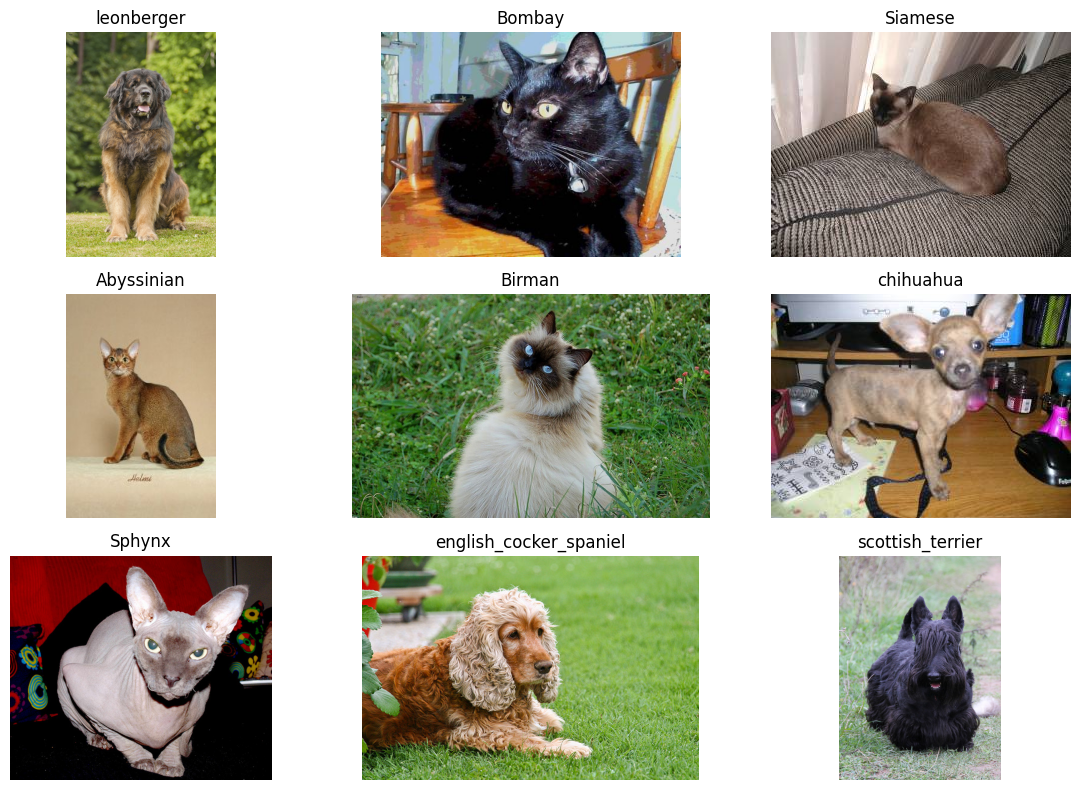

In [13]:
plt.figure(figsize=(12, 8))

for i in range(9):

    image = tf.keras.utils.load_img(
        df.iloc[i]["image_path"]
    )

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(df.iloc[i]["breed"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [128]:
class_names = df["breed"].unique().tolist()

print(class_names)

['great_pyrenees', 'american_pit_bull_terrier', 'american_bulldog', 'scottish_terrier', 'wheaten_terrier', 'keeshond', 'samoyed', 'english_setter', 'Sphynx', 'basset_hound', 'Russian_Blue', 'leonberger', 'Ragdoll', 'British_Shorthair', 'Bengal', 'pug', 'Bombay', 'Siamese', 'shiba_inu', 'chihuahua', 'Abyssinian', 'yorkshire_terrier', 'Egyptian_Mau', 'miniature_pinscher', 'Birman', 'Persian', 'beagle', 'boxer', 'havanese', 'saint_bernard', 'Maine_Coon', 'japanese_chin', 'english_cocker_spaniel', 'pomeranian', 'german_shorthaired', 'newfoundland', 'staffordshire_bull_terrier']


In [15]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 5912
Validation: 739
Testing: 739


In [54]:
print("Unique training labels:", train_df["label"].nunique())
print("Unique validation labels:", val_df["label"].nunique())
print("Unique test labels:", test_df["label"].nunique())

print("Training label range:",
      train_df["label"].min(),
      train_df["label"].max()
      )

Unique training labels: 37
Unique validation labels: 37
Unique test labels: 37
Training label range: 0 36


In [16]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
NUM_CLASSES = 37

In [17]:
def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    return image, label

In [18]:
def create_dataset(dataframe):

    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset



In [19]:
train_ds = create_dataset(train_df)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

In [20]:
for images, labels_batch in train_ds.take(1):

    print("Image shape:", images.shape)
    print("Label shape:", labels_batch.shape)

Image shape: (32, 180, 180, 3)
Label shape: (32,)


In [21]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        0.1
    ),

    tf.keras.layers.RandomZoom(
        0.1
    ),

    tf.keras.layers.RandomContrast(
        0.1
    )
])

In [22]:
model = tf.keras.Sequential([

    # Input
    tf.keras.layers.Input(
        shape=(180, 180, 3)
    ),

    # Data augmentation
    data_augmentation,

    # CNN Layer 1
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),

    # CNN Layer 2
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),

    # CNN Layer 3
    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),

    # CNN Layer 4
    tf.keras.layers.Conv2D(
        256,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),

    # Convert feature maps to vector
    tf.keras.layers.Flatten(),

    # Fully connected layer
    tf.keras.layers.Dense(
        256,
        activation="relu"
    ),

    # Prevent overfitting
    tf.keras.layers.Dropout(
        0.5
    ),

    # Output: 37 breeds
    tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

In [48]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     5,308,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,119,793 (65.31 MB)

 Trainable params: 5,706,597 (21.77 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 11,413,196 (43.54 MB)

In [50]:
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Input shape: (None, 180, 180, 3)
Output shape: (None, 37)


In [49]:
print("Total parameters:", model.count_params())

trainable_params = sum(
    tf.size(variable).numpy()
    for variable in model.trainable_weights
)

non_trainable_params = sum(
    tf.size(variable).numpy()
    for variable in model.non_trainable_weights
)

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

Total parameters: 5706597
Trainable parameters: 5706597
Non-trainable parameters: 0


In [23]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [24]:
early_stopping = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True
)

In [25]:
history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    callbacks=[early_stopping]
)

Epoch 1/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 32s 119ms/step - accuracy: 0.0458 - loss: 3.5755 - val_accuracy: 0.0677 - val_loss: 3.4856
Epoch 2/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 26s 78ms/step - accuracy: 0.0687 - loss: 3.4486 - val_accuracy: 0.0825 - val_loss: 3.3960
Epoch 3/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step - accuracy: 0.0864 - loss: 3.3581 - val_accuracy: 0.1015 - val_loss: 3.2979
Epoch 4/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.1062 - loss: 3.2738 - val_accuracy: 0.1340 - val_loss: 3.2457
Epoch 5/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accuracy: 0.1203 - loss: 3.1743 - val_accuracy: 0.1597 - val_loss: 3.0800
Epoch 6/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.1360 - loss: 3.0962 - val_accuracy: 0.1651 - val_loss: 3.0261
Epoch 7/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 80ms/step - accuracy: 0.1609 - loss: 3.0118 - val_accuracy: 0.1894 - val_loss: 2.9724
Epoch 8/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 20s 78ms/step - accuracy: 0.1742 - loss: 2.9495 -

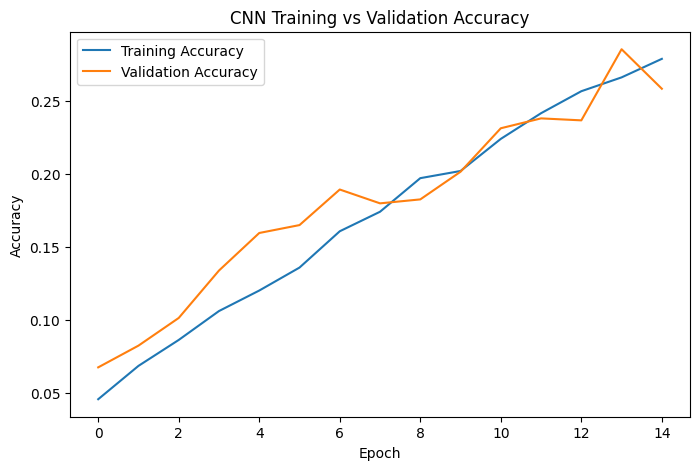

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")

plt.legend()
plt.show()

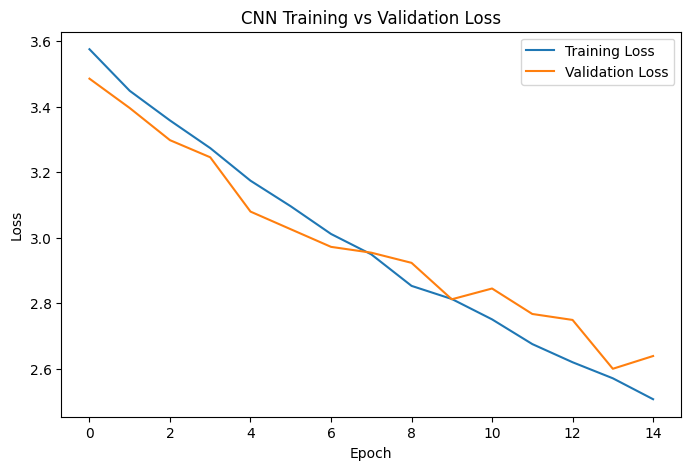

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")

plt.legend()
plt.show()

In [28]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.2774 - loss: 2.5036
Test Loss: 2.5035688877105713
Test Accuracy: 0.2774018943309784


#Transfer learning

###Feature Extraction

In [69]:
from keras.applications.resnet50 import ResNet50

In [70]:
conv_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

In [71]:
model_fe = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(180, 180, 3)),
        data_augmentation,
        tf.keras.layers.Rescaling(
        scale=255.0
    ),
        tf.keras.layers.Lambda(
        tf.keras.applications.resnet50.preprocess_input
    ),

        conv_base,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(37, activation="softmax")
    ]
)

In [72]:
model_fe.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_4 (Lambda)               │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 6, 6, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,765 (92.02 MB)

 Trainable params: 24,068,645 (91.81 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [73]:
print("Input shape:", model_fe.input_shape)
print("Output shape:", model_fe.output_shape)

Input shape: (None, 180, 180, 3)
Output shape: (None, 37)


In [74]:
print("Total parameters:", model_fe.count_params())

trainable_params = sum(
    tf.size(variable).numpy()
    for variable in model_fe.trainable_weights
)

non_trainable_params = sum(
    tf.size(variable).numpy()
    for variable in model_fe.non_trainable_weights
)

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

Total parameters: 24121765
Trainable parameters: 24068645
Non-trainable parameters: 53120


In [75]:
conv_base.trainable = False

In [76]:
model_fe.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [77]:
print("Optimizer:", model_fe.optimizer.__class__.__name__)
print("Loss function:", model_fe.loss)
print("Metrics:", model_fe.metrics_names)

print("ResNet50 trainable:", conv_base.trainable)

Optimizer: Adam
Loss function: sparse_categorical_crossentropy
Metrics: ['loss', 'compile_metrics']
ResNet50 trainable: False


In [78]:
history1 = model_fe.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 30s 125ms/step - accuracy: 0.5389 - loss: 1.6325 - val_accuracy: 0.8457 - val_loss: 0.5109
Epoch 2/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 116ms/step - accuracy: 0.7349 - loss: 0.8465 - val_accuracy: 0.8728 - val_loss: 0.4144
Epoch 3/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - accuracy: 0.7848 - loss: 0.6839 - val_accuracy: 0.8606 - val_loss: 0.4168
Epoch 4/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 22s 118ms/step - accuracy: 0.8077 - loss: 0.5965 - val_accuracy: 0.8579 - val_loss: 0.3990
Epoch 5/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 23s 124ms/step - accuracy: 0.8236 - loss: 0.5488 - val_accuracy: 0.8714 - val_loss: 0.3616
Epoch 6/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 40s 119ms/step - accuracy: 0.8319 - loss: 0.5168 - val_accuracy: 0.8701 - val_loss: 0.3836
Epoch 7/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - accuracy: 0.8420 - loss: 0.4848 - val_accuracy: 0.8687 - val_loss: 0.4129
Epoch 8/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 116ms/step - accuracy: 0.8427 - loss: 0

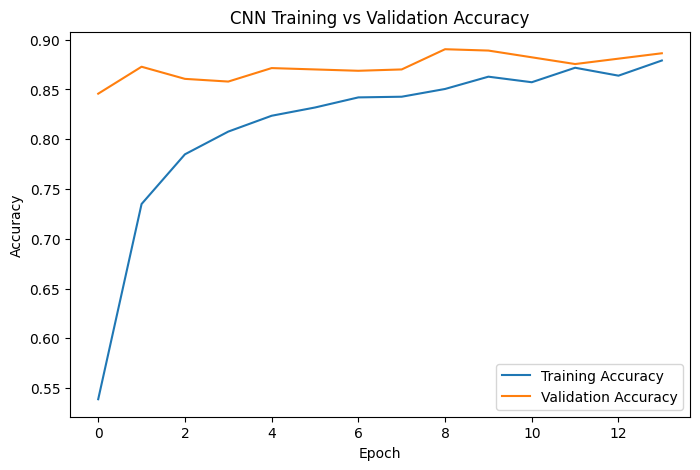

In [79]:
plt.figure(figsize=(8, 5))

plt.plot(
    history1.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history1.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")

plt.legend()
plt.show()

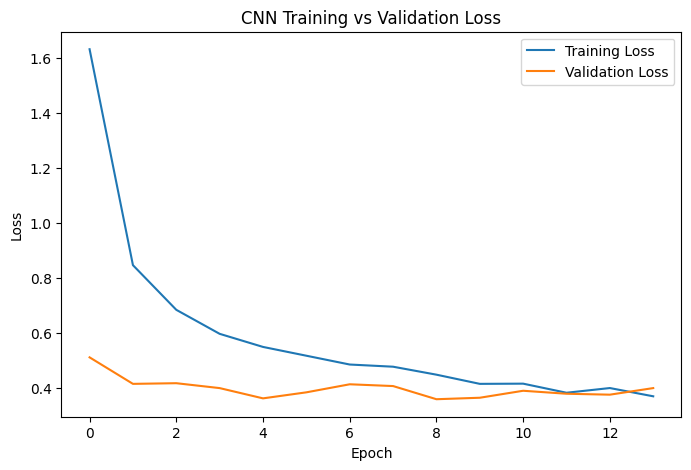

In [80]:
plt.figure(figsize=(8, 5))

plt.plot(
    history1.history["loss"],
    label="Training Loss"
)

plt.plot(
    history1.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")

plt.legend()
plt.show()

#Fine tuning for better validtion Accuracy

In [83]:
conv_base.trainable = True

set_trainable = False

for layer in conv_base.layers:
    if layer.name == "conv5_block1_out":
        set_trainable = True
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = set_trainable

for layer in conv_base.layers:
    print(layer.name, layer.trainable)

input_layer_9 False
conv1_pad False
conv1_conv False
conv1_bn False
conv1_relu False
pool1_pad False
pool1_pool False
conv2_block1_1_conv False
conv2_block1_1_bn False
conv2_block1_1_relu False
conv2_block1_2_conv False
conv2_block1_2_bn False
conv2_block1_2_relu False
conv2_block1_0_conv False
conv2_block1_3_conv False
conv2_block1_0_bn False
conv2_block1_3_bn False
conv2_block1_add False
conv2_block1_out False
conv2_block2_1_conv False
conv2_block2_1_bn False
conv2_block2_1_relu False
conv2_block2_2_conv False
conv2_block2_2_bn False
conv2_block2_2_relu False
conv2_block2_3_conv False
conv2_block2_3_bn False
conv2_block2_add False
conv2_block2_out False
conv2_block3_1_conv False
conv2_block3_1_bn False
conv2_block3_1_relu False
conv2_block3_2_conv False
conv2_block3_2_bn False
conv2_block3_2_relu False
conv2_block3_3_conv False
conv2_block3_3_bn False
conv2_block3_add False
conv2_block3_out False
conv3_block1_1_conv False
conv3_block1_1_bn False
conv3_block1_1_relu False
conv3_block1

In [84]:
model_fe.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-6
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [86]:
model_fe.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_4 (Lambda)               │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 6, 6, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,765 (92.02 MB)

 Trainable params: 9,453,093 (36.06 MB)

 Non-trainable params: 14,668,672 (55.96 MB)

In [87]:
history2 = model_fe.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 37s 151ms/step - accuracy: 0.8784 - loss: 0.3637 - val_accuracy: 0.8904 - val_loss: 0.3498
Epoch 2/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 25s 137ms/step - accuracy: 0.8831 - loss: 0.3547 - val_accuracy: 0.8945 - val_loss: 0.3463
Epoch 3/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 41s 137ms/step - accuracy: 0.8879 - loss: 0.3267 - val_accuracy: 0.8945 - val_loss: 0.3422
Epoch 4/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 26s 141ms/step - accuracy: 0.8799 - loss: 0.3460 - val_accuracy: 0.8945 - val_loss: 0.3413
Epoch 5/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 26s 141ms/step - accuracy: 0.8917 - loss: 0.3211 - val_accuracy: 0.8958 - val_loss: 0.3372
Epoch 6/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 26s 142ms/step - accuracy: 0.8921 - loss: 0.3078 - val_accuracy: 0.8945 - val_loss: 0.3342
Epoch 7/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 26s 143ms/step - accuracy: 0.8907 - loss: 0.3195 - val_accuracy: 0.8945 - val_loss: 0.3340
Epoch 8/10
185/185 ━━━━━━━━━━━━━━━━━━━━ 26s 142ms/step - accuracy: 0.8943 - loss: 0

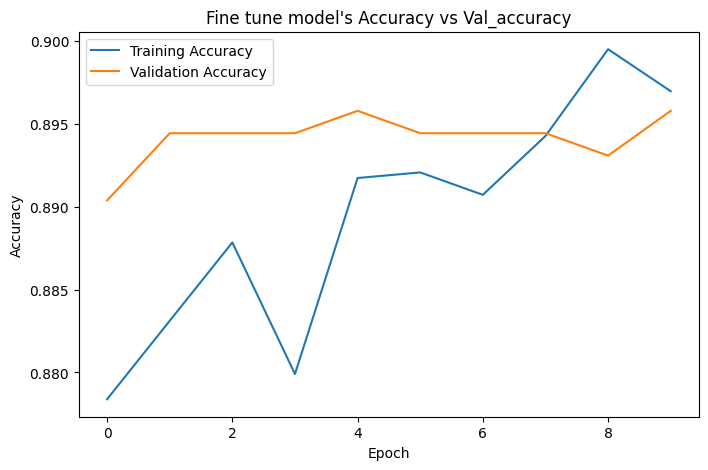

In [92]:
plt.figure(figsize=(8, 5))

plt.plot(
    history2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine tune model's Accuracy vs Val_accuracy")

plt.legend()
plt.show()

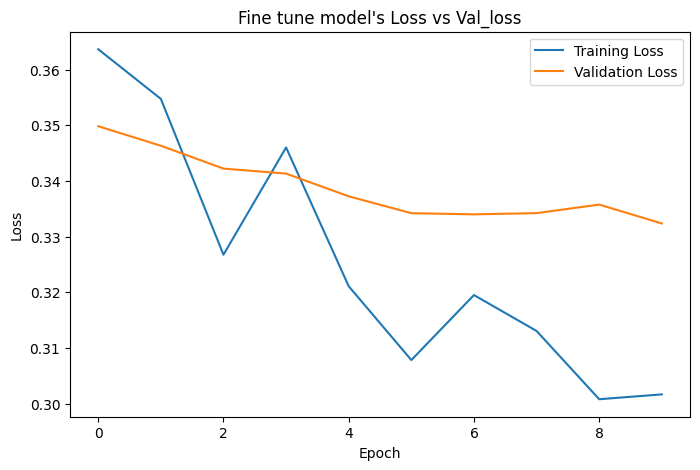

In [93]:
plt.figure(figsize=(8, 5))

plt.plot(
    history2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history2.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine tune model's Loss vs Val_loss")

plt.legend()
plt.show()

In [96]:
all_predictions = []
all_labels = []

for images, labels in test_ds:
    outputs = model_fe.predict(images, verbose=0)

    predictions = np.argmax(outputs, axis=1)

    all_predictions.extend(predictions)
    all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print("Test predictions completed!")

Test predictions completed!


In [98]:
print("Test Accuracy:", accuracy_score(all_labels, all_predictions))


Test Accuracy: 0.8903924221921515


In [102]:
print("\nClassification Report:")
print(classification_report(
                        all_labels,
                        all_predictions,
                        target_names= df["breed"].unique(),
                        zero_division=0
                        ))



Classification Report:
                            precision    recall  f1-score   support

            great_pyrenees       0.90      0.90      0.90        20
 american_pit_bull_terrier       0.86      0.90      0.88        20
          american_bulldog       0.79      0.75      0.77        20
          scottish_terrier       0.95      1.00      0.98        20
           wheaten_terrier       0.88      0.70      0.78        20
                  keeshond       0.90      0.90      0.90        20
                   samoyed       0.83      0.75      0.79        20
            english_setter       0.90      0.90      0.90        20
                    Sphynx       0.64      0.80      0.71        20
              basset_hound       0.77      0.85      0.81        20
              Russian_Blue       0.85      0.85      0.85        20
                leonberger       1.00      0.95      0.97        20
                   Ragdoll       0.81      0.85      0.83        20
         British_Shorth

In [106]:
print("\nConfusion Matrix:")
confusion_matrix(
                 all_labels,
                 all_predictions
                       )


Confusion Matrix:


array([[18,  0,  0, ...,  0,  0,  0],
       [ 1, 18,  0, ...,  0,  0,  0],
       [ 0,  0, 15, ...,  0,  0,  0],
       ...,
       [ 0,  0,  0, ..., 14,  0,  0],
       [ 0,  0,  0, ...,  0, 18,  0],
       [ 0,  0,  0, ...,  0,  0, 18]])

In [110]:
model_fe.save("/content/best_finetuned_model.keras")

In [115]:
best_model = tf.keras.models.load_model(
    "/content/best_finetuned_model.keras",
    custom_objects={
        "preprocess_input":
            tf.keras.applications.resnet50.preprocess_input
    }
)

In [116]:
test_loss, test_accuracy = best_model.evaluate(test_ds)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 141ms/step - accuracy: 0.8904 - loss: 0.3510
Test loss: 0.3510378301143646
Test accuracy: 0.8903924226760864


In [117]:
import os

model_path = "/content/best_finetuned_model.keras"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("File size (MB):",
          round(os.path.getsize(model_path) / (1024 * 1024), 2))

Model exists: True
File size (MB): 164.79


In [122]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [130]:
import json
import shutil

shutil.copy2(
    "/content/best_finetuned_model.keras",
    "/content/drive/MyDrive/best_finetuned_model.keras"
)

# Save your actual class names in the correct label order
with open("/content/drive/MyDrive/class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)


print("Model and class names saved!")

Model and class names saved!
